# Does a flood map transfer to a new flood?

Sentinel-1 radar sees through storm clouds; calm water reflects the radar pulse away and looks **dark**.
This notebook walks through the Sen1Floods11 benchmark (11 floods, six continents) and the question at the
heart of this project: how much worse does each water-mapping method get on a flood it has never seen?

It trains nothing — it reads the results written by `scripts/train.py`, `scripts/cross_event.py` and
`scripts/analyze.py` (run those first), plus the raw chips. Like the app, it never imports PyTorch or
LightGBM, which can't share a process on macOS (see the package docstring).

In [1]:
import json, sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from flood_radar_analytics import analysis, config, data
pd.set_option("display.precision", 3)
RESULTS = config.RESULTS_DIR

## 1. The data

In [2]:
names = data.all_names()
per_event = pd.Series([data.event_of(n) for n in names]).value_counts().loc[config.EVENTS]
print(f"{len(names)} chips"); per_event.to_frame("chips")

446 chips


,chips
Bolivia,15
Ghana,53
India,68
Mekong,30
Nigeria,18
Pakistan,28
Paraguay,67
Somalia,26
Spain,30
Sri-Lanka,42


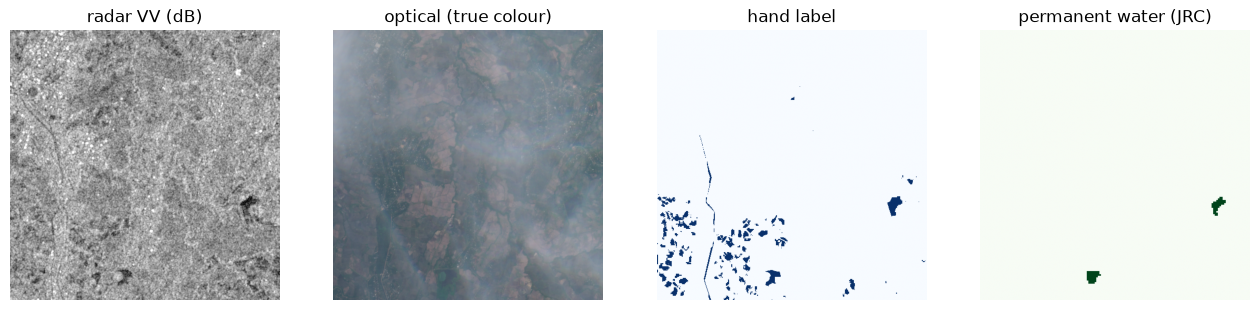

In [3]:
chip = data.load_chip("Sri-Lanka_120804_S1Hand.tif" if "Sri-Lanka_120804_S1Hand.tif" in names
                      else [n for n in names if n.startswith("Sri-Lanka")][0], with_s2=True)
idx = config.S2_BAND_INDEX
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
axes[0].imshow(np.clip(np.nan_to_num(chip.s1[0], nan=-25), -25, 0), cmap="gray"); axes[0].set_title("radar VV (dB)")
axes[1].imshow(np.clip(np.stack([chip.s2[idx[b]] for b in ("B4", "B3", "B2")], -1) / 0.3, 0, 1)); axes[1].set_title("optical (true colour)")
axes[2].imshow(np.where(chip.label < 0, np.nan, chip.label), cmap="Blues"); axes[2].set_title("hand label")
axes[3].imshow(chip.permanent_water, cmap="Greens"); axes[3].set_title("permanent water (JRC)")
for ax in axes: ax.axis("off")
plt.show()

## 2. How visible is water to radar, flood by flood?

In [4]:
sep = pd.read_csv(RESULTS / "event_separability.csv", index_col=0)
sep.sort_values("vv_auc")

,chips,water_share,vv_water_median_db,vv_land_median_db,vv_auc,contrast_db
event,,,,,,
Somalia,26,0.065,-14.474,-11.873,0.702,2.601
Paraguay,66,0.081,-16.316,-9.601,0.762,6.715
Pakistan,28,0.075,-15.784,-9.695,0.773,6.089
Sri-Lanka,42,0.118,-12.579,-8.676,0.813,3.904
Ghana,48,0.063,-15.204,-9.138,0.864,6.065
USA,69,0.046,-18.698,-10.759,0.869,7.939
Nigeria,18,0.236,-18.089,-9.848,0.880,8.241
India,68,0.124,-17.618,-8.343,0.889,9.275
Spain,30,0.132,-21.958,-10.113,0.926,11.845


VV AUC is how well VV alone ranks water above land (1.0 = one threshold separates them perfectly). It ranges
from about 0.70 to 0.97 — in some floods water is barely darker than land.

## 3. The official split: familiar floods

In [5]:
bench = json.loads((RESULTS / "benchmark.json").read_text())
pd.DataFrame({split: {m: s["pooled"]["IoU"] for m, s in methods.items()}
              for split, methods in bench["splits"].items()})

,valid,test,bolivia
VV threshold,0.465,0.464,0.441
Authors' Otsu,0.507,0.554,0.718
LightGBM (radar + texture),0.600,0.637,0.405
U-Net (radar),0.638,0.672,0.597
U-Net (radar + optical),0.815,0.830,0.811


## 4. Leave-one-event-out: new floods

In [6]:
cross = json.loads((RESULTS / "cross_event.json").read_text())
iou = lambda c: c["tp"] / max(c["tp"] + c["fp"] + c["fn"], 1)
held_out = pd.DataFrame({e: {m: iou(c) for m, c in d.items()} for e, d in cross["events"].items()}).T
held_out = held_out.loc[sep["vv_auc"].sort_values().index]
pooled = pd.Series({m: iou({k: sum(d[m][k] for d in cross["events"].values()) for k in ("tp", "fp", "fn")})
                    for m in held_out.columns})
held_out.loc["Pooled"] = pooled
held_out.style.format("{:.2f}").background_gradient(cmap="RdYlGn", vmin=0, vmax=1, axis=None)

,VV threshold,Authors' Otsu,LightGBM (radar + texture),U-Net (radar),U-Net (radar + optical)
event,,,,,
Somalia,0.15,0.15,0.22,0.27,0.70
Paraguay,0.43,0.45,0.55,0.53,0.60
Pakistan,0.24,0.15,0.30,0.32,0.65
Sri-Lanka,0.16,0.65,0.59,0.68,0.85
Ghana,0.35,0.41,0.39,0.49,0.68
USA,0.29,0.51,0.51,0.50,0.78
Nigeria,0.55,0.64,0.65,0.76,0.89
India,0.47,0.53,0.51,0.53,0.71
Spain,0.63,0.67,0.72,0.56,0.85


In [7]:
test = {m: s["pooled"]["IoU"] for m, s in bench["splits"]["test"].items()}
pd.DataFrame({"familiar floods (test)": test, "new floods (pooled held-out)": pooled}).assign(
    change=lambda t: t.iloc[:, 1] - t.iloc[:, 0])

,familiar floods (test),new floods (pooled held-out),change
VV threshold,0.464,0.434,-0.030
Authors' Otsu,0.554,0.495,-0.059
LightGBM (radar + texture),0.637,0.566,-0.071
U-Net (radar),0.672,0.587,-0.085
U-Net (radar + optical),0.830,0.775,-0.055


### Why fixed rules break: the right threshold moves

In [8]:
th = pd.DataFrame({"best for this flood": cross["oracle_threshold_db"],
                   "learned from the other 10": cross["fold_threshold_db"]}).loc[held_out.index[:-1]]
th["gap (dB)"] = th.iloc[:, 0] - th.iloc[:, 1]
th

,best for this flood,learned from the other 10,gap (dB)
event,,,
Somalia,-17.50,-16.25,-1.25
Paraguay,-17.50,-16.50,-1.00
Pakistan,-16.50,-16.50,0.00
Sri-Lanka,-12.50,-16.75,4.25
Ghana,-14.50,-16.75,2.25
USA,-18.25,-16.00,-2.25
Nigeria,-14.50,-16.75,2.25
India,-14.75,-16.75,2.00
Spain,-17.25,-16.50,-0.75


### The flood matters more than the method

In [9]:
per_event = held_out.drop(index="Pooled")
{m: round(per_event[m].corr(sep.loc[per_event.index, "vv_auc"]), 2) for m in per_event.columns}

{'VV threshold': np.float64(0.77),
 "Authors' Otsu": np.float64(0.84),
 'LightGBM (radar + texture)': np.float64(0.68),
 'U-Net (radar)': np.float64(0.75),
 'U-Net (radar + optical)': np.float64(0.68)}

## 5. Where is water missed?

In [10]:
for path in sorted(RESULTS.glob("error_anatomy_*.json")):
    a = json.loads(path.read_text())
    print(path.stem.removeprefix("error_anatomy_"))
    print("  recall by water type:", {r["water type"]: round(r["recall"], 3) for r in a["by_water_type"]})

authors_otsu
  recall by water type: {'new floodwater': 0.604, 'permanent water': 0.989}


lightgbm_radar_plus_texture
  recall by water type: {'new floodwater': 0.52, 'permanent water': 0.941}
u_net_radar
  recall by water type: {'new floodwater': 0.62, 'permanent water': 0.907}
u_net_radar_plus_optical
  recall by water type: {'new floodwater': 0.81, 'permanent water': 0.995}
vv_threshold
  recall by water type: {'new floodwater': 0.446, 'permanent water': 0.753}


In [11]:
best = json.loads((RESULTS / "error_anatomy_u_net_radar_plus_optical.json").read_text())
pd.DataFrame(best["by_vegetation"]).set_index("ndvi")

,clear-sky pixels,water share,recall,false-alarm rate
ndvi,,,,
bare / water (< 0.2),11588227,0.639,0.912,8.451e-02
sparse (0.2-0.4),18090956,0.019,0.243,2.831e-02
moderate (0.4-0.6),28424585,0.004,0.054,2.052e-03
dense (> 0.6),24687506,0.002,0.013,1.603e-04


## 6. Takeaways

- On familiar floods, each step up in model complexity helps, and optical bands help most.
- On a new flood, every learned fixed rule can be badly wrong: the brightness of water in radar shifts by
  several dB between floods, while a threshold learned from other floods is always about the same number.
- How separable water is in a flood's radar predicts a method's score on it better than the choice of method.